<a href="https://colab.research.google.com/github/lalarconl/deep-learning-doctorado/blob/main/Regularization_CNN_Luis_Alarcon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on Worksheet — Regularization in CNN
**Session 8 – 25/10/2026** · Course: Artificial Intelligence and Deep Learning · PhD Program, FISI–UNMSM
**Student:** Luis Alberto Alarcón Loayza

**Aim:** To investigate how regularization affects a CNN's ability to generalize from training data to unseen data using the MNIST handwritten-digit dataset.

We compare three models with the same architecture: **A. Baseline** (no regularization), **B. Dropout**, and **C. Data augmentation + Dropout**.

## Step 1 — Setup
TensorFlow is preinstalled in Google Colab. If an import error appears, run `!pip install tensorflow matplotlib` in a separate cell.

## Step 2 — Load and prepare the data
MNIST contains 28 × 28 grayscale images of handwritten digits (0–9). Pixel values are normalized to the range 0–1. The data is split into three sets:
- **Training:** 3,000 images, used to update the model weights.
- **Validation:** 1,000 images, used to monitor generalization (they do not update the weights).
- **Test:** 10,000 images, used once at the end for the final evaluation.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training: (3000, 28, 28, 1)
Validation: (1000, 28, 28, 1)
Test: (10000, 28, 28, 1)


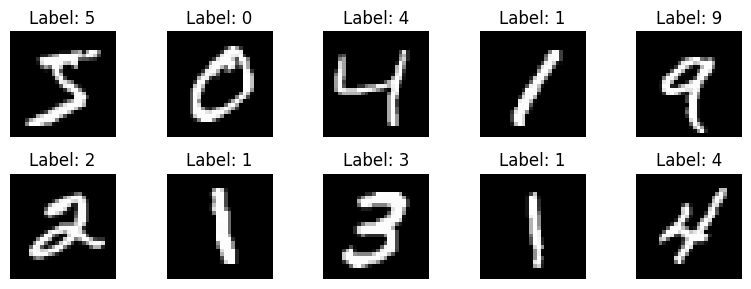

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, regularizers

tf.keras.utils.set_random_seed(42)

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]
# Use a smaller subset to keep the practical manageable
x_train_small, y_train_small = x_train[:3000], y_train[:3000]
x_val, y_val = x_train[3000:4000], y_train[3000:4000]

print("Training:", x_train_small.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)

plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_small[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train_small[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Step 3 — Build three models
All three models share the same architecture: Conv2D(32) → MaxPooling → Conv2D(64) → MaxPooling → Flatten → Dense(128) → Dense(10, softmax).
- **A. Baseline:** no regularization.
- **B. Dropout:** adds `Dropout(0.4)` after the dense layer, active only during training.
- **C. Augmentation + Dropout:** additionally applies `RandomTranslation(0.05, 0.05)`, which shifts each image by up to 5% during training.

Dropout and data augmentation add no trainable parameters, so the three models have the same number of parameters.

In [ ]:
def build_cnn(dropout_rate=0.0, use_augmentation=False, l2_strength=0.0):
    model = models.Sequential()
    model.add(layers.Input(shape=(28, 28, 1)))

    if use_augmentation:
        model.add(layers.RandomTranslation(0.05, 0.05))

    model.add(layers.Conv2D(
        32, (3, 3), activation="relu",
        kernel_regularizer=regularizers.l2(l2_strength)))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(
        64, (3, 3), activation="relu",
        kernel_regularizer=regularizers.l2(l2_strength)))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation="relu"))
    if dropout_rate > 0:
        model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(10, activation="softmax"))

    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

baseline = build_cnn()
dropout_model = build_cnn(dropout_rate=0.4)
augmented_model = build_cnn(dropout_rate=0.4, use_augmentation=True)

", augmented_model.count_params())print("Baseline parameters:", baseline.count_params())
print("Dropout parameters:", dropout_model.count_params())
print("Augmentation + dropout parameters:

Baseline parameters: 225034
Dropout parameters: 225034
Augmentation + dropout parameters: 225034


## Step 4 — Train the models
Each model is trained for 10 epochs with a batch size of 64. Validation accuracy and loss are measured at the end of each epoch to monitor performance; validation data does not update the model weights.

In [ ]:
EPOCHS = 10
BATCH_SIZE = 64

models_to_compare = {
    "Baseline": baseline,
    "Dropout": dropout_model,
    "Augmentation + Dropout": augmented_model
}
histories = {}

for name, model in models_to_compare.items():
    print("\nTraining:", name)
    result = model.fit(
        x_train_small, y_train_small,
        validation_data=(x_val, y_val),
        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1)
    histories[name] = result.history


Training: Baseline
Epoch 1/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - accuracy: 0.7097 - loss: 1.0362 - val_accuracy: 0.8970 - val_loss: 0.3116
Epoch 2/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 57ms/step - accuracy: 0.9200 - loss: 0.2795 - val_accuracy: 0.9380 - val_loss: 0.1939
Epoch 3/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 0.9567 - loss: 0.1657 - val_accuracy: 0.9530 - val_loss: 0.1340
Epoch 4/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.9697 - loss: 0.1176 - val_accuracy: 0.9650 - val_loss: 0.1068
Epoch 5/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.9773 - loss: 0.0874 - val_accuracy: 0.9690 - val_loss: 0.0904
Epoch 6/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.9847 - loss: 0.0643 - val_accuracy: 0.9770 - val_loss: 0.0832
Epoch 7/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.9897 - loss: 0.0473 - val_accuracy: 0.9740 - val_loss: 0.0809
Epoch 8/10
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.9933 - loss: 0.0351 - val_

## Step 5 — Plot and compare results
If the training accuracy keeps increasing (or the training loss keeps decreasing) while the validation curve stalls or gets worse, the model is overfitting.

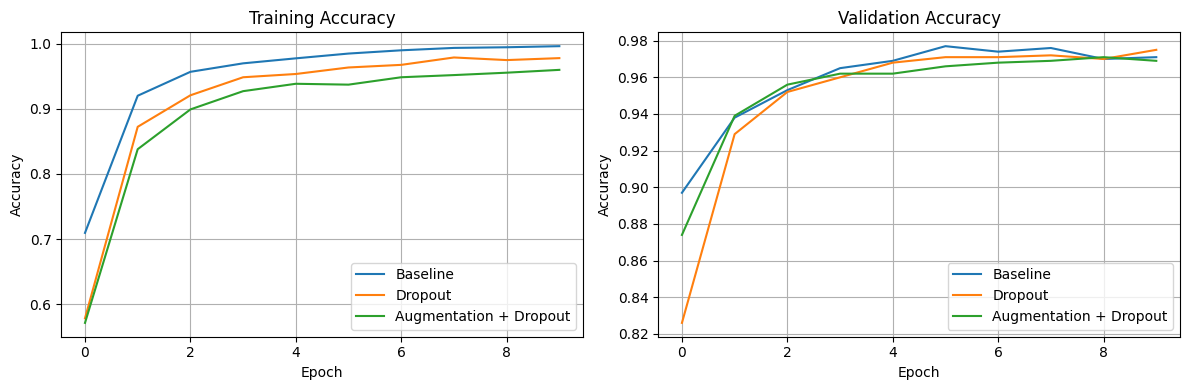

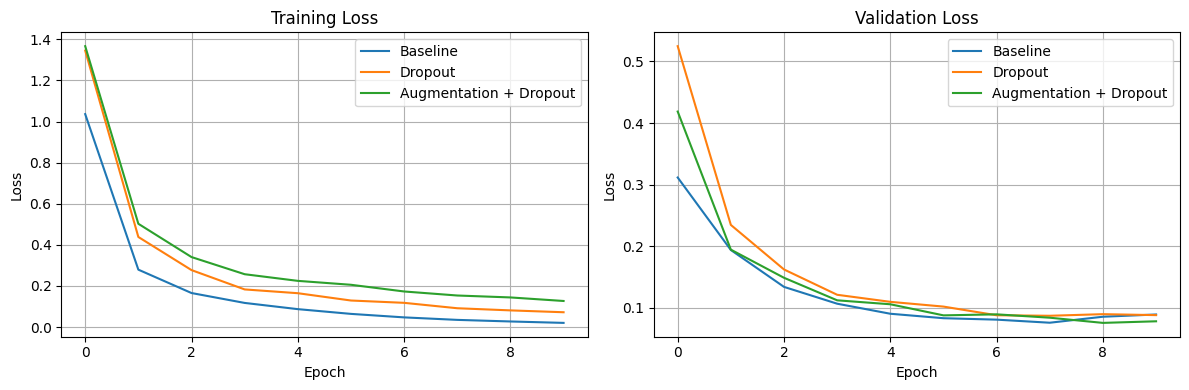

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    axes[0].plot(history["accuracy"], label=name)
    axes[1].plot(history["val_accuracy"], label=name)
axes[0].set_title("Training Accuracy")
axes[1].set_title("Validation Accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    axes[0].plot(history["loss"], label=name)
    axes[1].plot(history["val_loss"], label=name)
axes[0].set_title("Training Loss")
axes[1].set_title("Validation Loss")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

## Step 6 — Evaluate on the test set
The test set (10,000 unseen images) is evaluated only once, after comparing the models. The models are not tuned based on these results.

In [ ]:
test_results = {}
for name, model in models_to_compare.items():
    test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
    test_results[name] = (test_accuracy, test_loss)
    print(f"{name:25s} Test accuracy: {test_accuracy:.4f} | "
          f"Test loss: {test_loss:.4f}")

Baseline                  Test accuracy: 0.9638 | Test loss: 0.1190
Dropout                   Test accuracy: 0.9691 | Test loss: 0.0984
Augmentation + Dropout    Test accuracy: 0.9709 | Test loss: 0.0859


## Results table (automatic summary)
This additional cell collects the values for the worksheet table from this run:
- *Final train accuracy*: training accuracy in the last epoch.
- *Best validation accuracy*: highest validation accuracy over the 10 epochs.
- *Gap*: training minus validation accuracy in the last epoch (a large gap suggests overfitting).

In [ ]:
import pandas as pd

rows = []
for name in models_to_compare:
    h = histories[name]
    rows.append({
        "Model": name,
        "Final train accuracy": h["accuracy"][-1],
        "Best validation accuracy": max(h["val_accuracy"]),
        "Best val. epoch": int(np.argmax(h["val_accuracy"])) + 1,
        "Final validation accuracy": h["val_accuracy"][-1],
        "Gap (train - val, last epoch)": h["accuracy"][-1] - h["val_accuracy"][-1],
        "Final train loss": h["loss"][-1],
        "Final validation loss": h["val_loss"][-1],
        "Test accuracy": test_results[name][0],
        "Test loss": test_results[name][1],
    })

results_df = pd.DataFrame(rows).set_index("Model").round(4)
results_df

,Final train accuracy,Best validation accuracy,Best val. epoch,Final validation accuracy,"Gap (train - val, last epoch)",Final train loss,Final validation loss,Test accuracy,Test loss
Model,,,,,,,,,
Baseline,0.9960,0.977,6,0.971,0.0250,0.0205,0.0893,0.9638,0.1190
Dropout,0.9777,0.975,10,0.975,0.0027,0.0722,0.0882,0.9691,0.0984
Augmentation + Dropout,0.9597,0.971,9,0.969,-0.0093,0.1271,0.0782,0.9709,0.0859


## Optional extension — Early stopping
A fresh dropout model is trained for up to 20 epochs. Training stops automatically if the validation loss does not improve for 2 consecutive epochs, and the weights from the best epoch are restored.

In [ ]:
early_stop_model = build_cnn(dropout_rate=0.4)
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True)

early_history = early_stop_model.fit(
    x_train_small, y_train_small,
    validation_data=(x_val, y_val),
    epochs=20, batch_size=64,
    callbacks=[early_stopping], verbose=1)

print("Epochs completed:", len(early_history.history["loss"]))
print("Best validation loss:", min(early_history.history["val_loss"]))
print("Best epoch:", int(np.argmin(early_history.history["val_loss"])) + 1)

Epoch 1/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - accuracy: 0.6113 - loss: 1.2602 - val_accuracy: 0.8680 - val_loss: 0.4600
Epoch 2/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.8843 - loss: 0.3980 - val_accuracy: 0.9370 - val_loss: 0.2112
Epoch 3/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.9303 - loss: 0.2468 - val_accuracy: 0.9520 - val_loss: 0.1561
Epoch 4/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.9493 - loss: 0.1785 - val_accuracy: 0.9620 - val_loss: 0.1265
Epoch 5/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9563 - loss: 0.1479 - val_accuracy: 0.9650 - val_loss: 0.1077
Epoch 6/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 77ms/step - accuracy: 0.9677 - loss: 0.1191 - val_accuracy: 0.9690 - val_loss: 0.0981
Epoch 7/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.9673 - loss: 0.1062 - val_accuracy: 0.9690 - val_loss: 0.0983
Epoch 8/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.9737 - loss: 0.0896 - val_accuracy: 0.9670 - v